# At-risk order model (Q4, part 2)

**Goal:** at the moment an order is delivered, predict whether the customer will leave a 1–2 star review, so customer service can contact the riskiest orders first.

**Rules:**
- Every feature must be known at delivery time. Review scores, review dates and anything derived from them are never used as features (that would be target leakage).
- Orders whose review was written before delivery are excluded, because the use case is acting at delivery.
- The model is trained on older orders and tested on newer ones, as it would be used in production.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

con = duckdb.connect("../warehouse/olist.duckdb", read_only=True)
FIG = "../reports/figures/"

df = con.sql("""
    WITH main_item AS (       -- the most expensive item decides the order's category
        SELECT i.order_id, p.category, s.state AS seller_state
        FROM marts.fct_order_items i
        JOIN marts.dim_products p USING (product_id)
        JOIN marts.dim_sellers  s USING (seller_id)
        QUALIFY row_number() OVER (PARTITION BY i.order_id
                                   ORDER BY i.price DESC, i.order_item_id) = 1
    )
    SELECT f.order_id,
           f.purchase_date,
           f.is_negative_review::INT       AS target,
           f.delivery_days,
           f.promised_days,
           f.delay_days,
           f.is_late::INT                  AS is_late,
           f.items_value::DOUBLE           AS items_value,
           f.freight_value::DOUBLE         AS freight_value,
           f.n_items,
           f.n_sellers,
           f.max_installments,
           f.main_payment_type,
           c.state                         AS customer_state,
           m.category,
           (m.seller_state = c.state)::INT AS same_state
    FROM marts.fct_orders f
    JOIN marts.dim_customers c       USING (customer_unique_id)
    JOIN main_item m                 USING (order_id)
    JOIN staging.stg_order_reviews r USING (order_id)
    WHERE f.order_status = 'delivered'
      AND f.delivered_at IS NOT NULL
      AND CAST(r.review_created_at AS DATE) >= CAST(f.delivered_at AS DATE)
""").df()

df["purchase_date"] = pd.to_datetime(df["purchase_date"])
df["freight_ratio"] = df["freight_value"] / df["items_value"].clip(lower=1)

print(f"{len(df):,} orders, {df['target'].mean():.1%} got a 1-2 star review")
df.head()

90,848 orders, 9.5% got a 1-2 star review


,order_id,purchase_date,target,delivery_days,promised_days,delay_days,is_late,items_value,freight_value,n_items,n_sellers,max_installments,main_payment_type,customer_state,category,same_state,freight_ratio
0,a3868921c7af20ac7aafb5e8b7b5b4ba,2018-02-04,0,12,36,-24,0,49.00,15.10,1,1,1,credit_card,RJ,construction_tools_construction,0,0.308163
1,29ae0692b28230c48573dd73920619c2,2018-02-06,1,15,34,-19,0,299.80,55.18,2,1,1,boleto,RJ,computers_accessories,0,0.184056
2,11a712e608d2c5d35b89246489db966d,2017-12-28,1,29,53,-24,0,129.99,57.58,1,1,1,boleto,RJ,baby,0,0.442957
3,fb362fb533a2d245c5822558de85ce16,2017-11-06,0,7,25,-18,0,124.99,14.62,1,1,1,boleto,RJ,consoles_games,0,0.116969
4,08a79aa47b2dc809df77206f0660fe5b,2018-05-01,0,21,29,-8,0,64.99,27.51,1,1,1,boleto,RJ,health_beauty,0,0.423296


In [2]:
NUMERIC = ["delivery_days", "promised_days", "delay_days", "is_late", "items_value",
           "freight_value", "freight_ratio", "n_items", "n_sellers", "max_installments", "same_state"]
CATEGORICAL = ["main_payment_type", "customer_state", "category"]
FEATURES = NUMERIC + CATEGORICAL

cutoff = pd.Timestamp("2018-04-01")
train = df[df["purchase_date"] < cutoff]
test = df[df["purchase_date"] >= cutoff].copy()
X_train, y_train = train[FEATURES], train["target"]
X_test, y_test = test[FEATURES], test["target"]

print(f"train {len(train):,} orders, test {len(test):,} orders, "
      f"positive rate {y_train.mean():.1%} / {y_test.mean():.1%}")

train 59,784 orders, test 31,064 orders, positive rate 9.9% / 8.7%


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

one_hot = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False)

logreg = Pipeline([
    ("prep", ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), NUMERIC),
        ("cat", one_hot, CATEGORICAL),
    ])),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

boosting = Pipeline([
    ("prep", ColumnTransformer([
        ("num", "passthrough", NUMERIC),      # gradient boosting handles missing values itself
        ("cat", one_hot, CATEGORICAL),
    ])),
    ("model", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300,
                                             class_weight="balanced", random_state=42)),
])

models = {"Logistic regression": logreg, "Gradient boosting": boosting}
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    p = model.predict_proba(X_test)[:, 1]
    results.append({"model": name,
                    "ROC AUC": roc_auc_score(y_test, p),
                    "PR AUC": average_precision_score(y_test, p)})

print(pd.DataFrame(results).round(3))
print("PR AUC of random guessing =", round(y_test.mean(), 3))

                 model  ROC AUC  PR AUC
0  Logistic regression    0.661   0.196
1    Gradient boosting    0.645   0.202
PR AUC of random guessing = 0.087


## Model results

Trained on 59,784 orders before April 2018 and tested on 31,064 orders from April 2018 onwards (bad-review rate 9.9% in training, 8.7% in test).

| Model | ROC AUC | PR AUC |
| --- | --- | --- |
| Random guessing | 0.500 | 0.087 |
| Logistic regression | 0.661 | 0.196 |
| Gradient boosting | 0.645 | 0.202 |

- **Both models find bad reviews about 2.3x more often than random** (PR AUC ~0.20 vs 0.087). PR AUC is used as the main metric because the target is imbalanced.
- **Gradient boosting adds almost nothing over logistic regression**, suggesting the signal is simple and dominated by delivery delay.
- **The achievable accuracy is limited by the data:** about two-thirds of bad reviews come from orders delivered on time, for reasons not captured here (product quality, wrong items, seller communication).

In [4]:
late = test["is_late"] == 1
n_bad = y_test.sum()
print(f"'Late = unhappy' rule: flags {late.mean():.1%} of orders, "
      f"precision {y_test[late].mean():.0%}, catches {y_test[late].sum() / n_bad:.0%} of bad reviews")

for name, model in models.items():
    test[f"risk_{name}"] = model.predict_proba(X_test)[:, 1]
    for share in (0.05, 0.10, 0.20):
        flagged = test[f"risk_{name}"] >= test[f"risk_{name}"].quantile(1 - share)
        print(f"{name}, top {share:.0%}: precision {y_test[flagged].mean():.0%}, "
              f"catches {y_test[flagged].sum() / n_bad:.0%} of bad reviews")

'Late = unhappy' rule: flags 1.5% of orders, precision 20%, catches 4% of bad reviews
Logistic regression, top 5%: precision 31%, catches 18% of bad reviews
Logistic regression, top 10%: precision 24%, catches 27% of bad reviews
Logistic regression, top 20%: precision 18%, catches 41% of bad reviews
Gradient boosting, top 5%: precision 32%, catches 18% of bad reviews
Gradient boosting, top 10%: precision 25%, catches 29% of bad reviews
Gradient boosting, top 20%: precision 18%, catches 41% of bad reviews


In [5]:
con.sql("""
    SELECT f.is_late,
           count(*) AS reviewed_orders,
           count(*) FILTER (WHERE CAST(r.review_created_at AS DATE) >= CAST(f.delivered_at AS DATE)) AS kept,
           round(100.0 * avg(f.is_negative_review::INT), 1) AS pct_negative_all,
           round(100.0 * avg(f.is_negative_review::INT) FILTER (
               WHERE CAST(r.review_created_at AS DATE) >= CAST(f.delivered_at AS DATE)), 1) AS pct_negative_kept
    FROM marts.fct_orders f
    JOIN staging.stg_order_reviews r USING (order_id)
    WHERE f.order_status = 'delivered' AND f.delivered_at IS NOT NULL
    GROUP BY 1
""").df()

,is_late,reviewed_orders,kept,pct_negative_all,pct_negative_kept
0,True,6381,1630,62.4,25.1
1,False,89443,89218,9.3,9.2


## Comparing with a simple rule, and a design correction

Contacting the **top 10% riskiest orders** reaches an unhappy customer **25% of the time (2.9x the 8.7% base rate)** and catches **29% of all bad reviews**. The top 5% gives 32% precision (3.7x lift).

The "flag late orders" rule looked weak here (1.5% of test orders, 20% precision), even though Q4 showed late orders get bad reviews 49–79% of the time. Checking why revealed a timing issue:

| Orders | Reviewed | Kept by the "reviewed after delivery" filter | Bad reviews (all) | Bad reviews (kept) |
| --- | --- | --- | --- | --- |
| Late | 6,381 | 1,630 (25.5%) | 62.4% | 25.1% |
| On time | 89,443 | 89,218 (99.7%) | 9.3% | 9.2% |

Olist sends the review survey around the **promised** delivery date, so when an order is late, most customers review **before the parcel arrives**, and those are the angriest. About 3,600 of the ~4,000 bad reviews on late orders are written before delivery, so no model that waits for delivery can catch them.

**Revised strategy: two interventions**
1. **Late orders, no model needed:** contact every order the day it misses its promised date, before it arrives. 62% of these customers leave a bad review, so almost every contact reaches someone at risk.
2. **Orders delivered on time, use the model:** rank them by predicted risk and contact the top 5–10%, catching unhappy customers that delivery timing alone cannot flag.

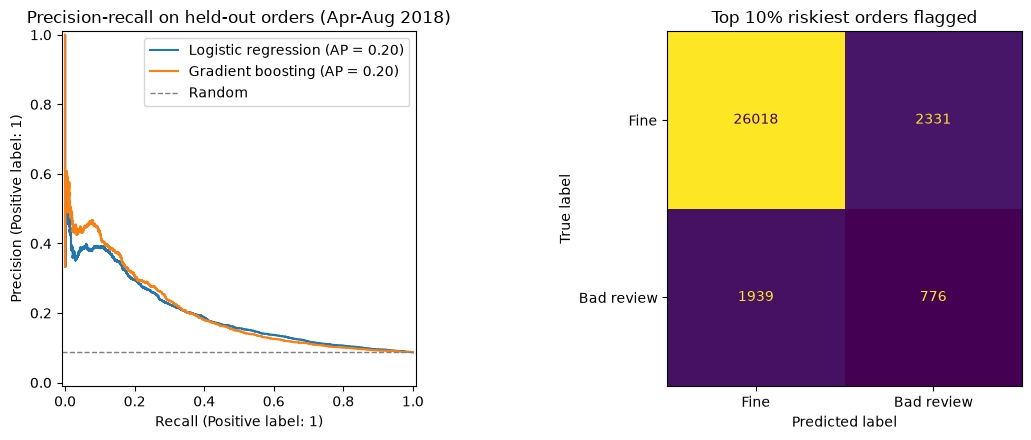

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay

best = models["Gradient boosting"]
flagged = test["risk_Gradient boosting"] >= test["risk_Gradient boosting"].quantile(0.90)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, model in models.items():
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, name=name, ax=axes[0])
axes[0].axhline(y_test.mean(), ls="--", color="grey", lw=1, label="Random")
axes[0].legend()
axes[0].set_title("Precision-recall on held-out orders (Apr-Aug 2018)")
ConfusionMatrixDisplay.from_predictions(y_test, flagged.astype(int),
                                        display_labels=["Fine", "Bad review"],
                                        ax=axes[1], colorbar=False)
axes[1].set_title("Top 10% riskiest orders flagged")
fig.tight_layout()
fig.savefig(FIG + "model_evaluation.png", dpi=150)

n_items              0.0859
n_sellers            0.0270
delivery_days        0.0186
items_value          0.0028
delay_days           0.0026
category             0.0025
customer_state       0.0018
promised_days        0.0016
same_state           0.0005
freight_value        0.0005
max_installments     0.0001
is_late              0.0000
main_payment_type   -0.0001
freight_ratio       -0.0007
dtype: float64

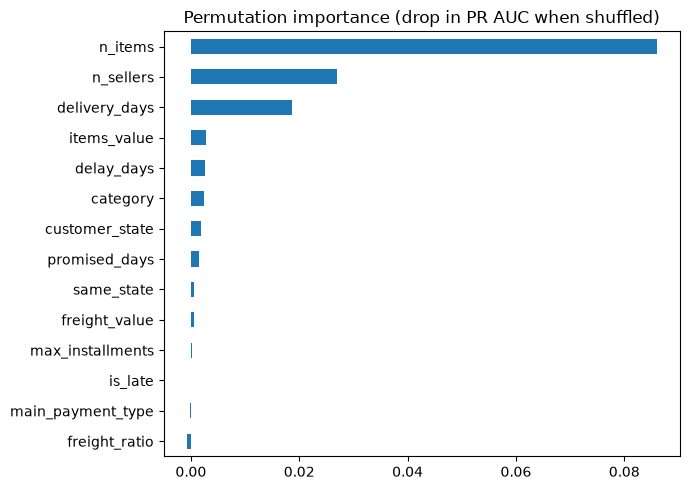

In [7]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(best, X_test, y_test, scoring="average_precision",
                             n_repeats=5, random_state=42, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
importance.plot.barh(ax=ax)
ax.set_title("Permutation importance (drop in PR AUC when shuffled)")
fig.tight_layout()
fig.savefig(FIG + "feature_importance.png", dpi=150)
importance.sort_values(ascending=False).round(4)

In [8]:
check = df.assign(
    items=np.where(df["n_items"] >= 3, "3+", df["n_items"].astype(str)),
    sellers=np.where(df["n_sellers"] > 1, "2+ sellers", "1 seller"),
)
pd.concat([
    check.groupby("items")["target"].agg(orders="count", pct_bad=lambda s: round(100 * s.mean(), 1)),
    check.groupby("sellers")["target"].agg(orders="count", pct_bad=lambda s: round(100 * s.mean(), 1)),
])

,orders,pct_bad
1,81694,7.8
2,7024,23.5
3+,2130,29.6
1 seller,89602,9.0
2+ sellers,1246,47.1


## What drives the predictions

Permutation importance shows the model relies mostly on **order size**, not delay: `n_items` (0.086) and `n_sellers` (0.027) matter most, followed by `delivery_days` (0.019). Delay matters little here because most late orders were removed by the "reviewed after delivery" filter.

Checking the raw rates confirms a **finding that the Phase 4 analysis missed**:

| Order type | Orders | Bad-review rate |
| --- | --- | --- |
| 1 item | 81,694 | 7.8% |
| 2 items | 7,024 | 23.5% (3.0x) |
| 3+ items | 2,130 | 29.6% (3.8x) |
| 1 seller | 89,602 | 9.0% |
| 2+ sellers | 1,246 | **47.1% (5.2x)** |

**Multi-item orders are 10% of orders but about 26% of bad reviews.** A likely explanation (not yet verified) is split shipments: each seller ships separately, so customers may review when the first parcel arrives with items still missing. Analysing the review comment text would test this.

## Model summary

- **Use case:** at delivery, rank orders by risk of a 1–2 star review so customer service can intervene first.
- **Result:** contacting the top 10% riskiest orders reaches an unhappy customer 25% of the time (2.9x the base rate) and catches 29% of bad reviews; the top 5% gives 32% precision (3.7x).
- **Two-part strategy:** contact late orders the day they miss their promised date (62% would leave a bad review, mostly before delivery), and use the model for orders delivered on time.
- **Business recommendation beyond the model:** multi-seller orders get bad reviews 47% of the time. Consolidating shipments, or warning customers that items will arrive separately, could prevent a large share of bad reviews at the source.
- **Limitations:** about two-thirds of bad reviews come from causes the data cannot see (product quality, wrong items), which caps achievable accuracy at roughly PR AUC 0.20.